# 03 · Camembert: Hessians and local uncertainty

**Goal.** Compute exact and Gauss–Newton Hessian actions, explain their difference, and turn a declared likelihood and proper prior into a local covariance. We use the calibrated **48 × 48 Camembert** model, eight surrounding sources and 32 receivers at **5 Hz**.

**What this demonstrates:** derivative consistency and conditional local uncertainty in a **4 × 4 active window**. Synthetic data use the same discretization; this is an algebraic tutorial, not a reconstruction-accuracy or uncertainty-coverage experiment. All other cells are assumed known exactly.

**Run:** select the repository's Python environment and **Restart Kernel → Run All**. Start Jupyter from the repository root or `notebooks/`. The default is CPU `float64/complex128`; it creates no cloud resources. Expect roughly a minute, depending on CPU/BLAS configuration. Only the tiny 16-parameter diagnostic assembles dense matrices; the production APIs apply operators without assembling a full-grid Hessian.

[Notebook index](README.md) · [Uncertainty guide](../guides/uncertainty.md) · [Validation evidence](../guides/validation.md)

In [1]:
# Set numerical thread limits before importing numerical libraries.
import os
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[name] = "1"
from pathlib import Path
import json, platform, sys, time

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "simplefwi/fwi2d").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the SimpleFWI checkout.")
sys.path.insert(0, str(ROOT))

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from IPython.display import Markdown, display
from simplefwi.fwi2d import (
    Acquisition, BoundaryConfig, Grid2D, SolverConfig,
    Curvature, FWIObjective, LocalGaussian, CGConfig,
)
from simplefwi.fwi2d.curvature import explicit_matrix
from simplefwi.fwi2d.operator import HelmholtzOperator
from simplefwi.fwi2d.solvers import DirectSolver

torch.set_num_threads(1)
torch.manual_seed(19)
np.random.seed(19)
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.titlesize": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
START = time.perf_counter()
print(f"Python {platform.python_version()} | PyTorch {torch.__version__}")
print(f"Interpreter: {sys.executable}")
print("CPU · real float64 / complex128 · seed 19 · one numerical thread")

Python 3.12.14 | PyTorch 2.12.0+cpu
Interpreter: /workspace/SimpleFWI/.venv/bin/python
CPU · real float64 / complex128 · seed 19 · one numerical thread


## 1. From a wave equation to a covariance

Let $m=v^{-2}$ in s²/m², $d(m)$ be the complex receiver data, and $J=\partial d/\partial m$. For a fixed whitening operator $W$,

$$\Phi_d(m)=\tfrac12\|W[d(m)-d_{\rm obs}]\|_2^2,$$
$$H_{\rm GN}=\operatorname{Re}(J^H W^H WJ),\qquad H_{\rm exact}=H_{\rm GN}+H_{\rm residual}.$$

The residual term can make the exact Hessian indefinite away from a solution. At zero residual it vanishes. A local Gaussian approximation uses a **proper prior** with precision $P$, giving $C_{\rm GN}=(H_{\rm GN}+P)^{-1}$. An exact Laplace covariance additionally requires an appropriate stationary reference and positive posterior Hessian; an arbitrary exact Hessian is not a covariance model.

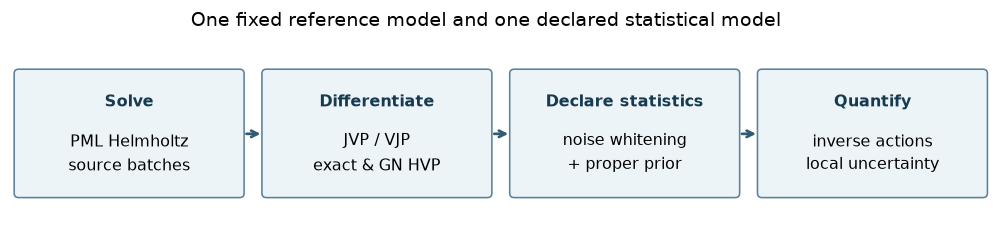

In [2]:
fig, ax = plt.subplots(figsize=(11, 2.1))
ax.set(xlim=(0, 11), ylim=(0, 2.1)); ax.axis("off")
labels = [("Solve", "PML Helmholtz\nsource batches"),
          ("Differentiate", "JVP / VJP\nexact & GN HVP"),
          ("Declare statistics", "noise whitening\n+ proper prior"),
          ("Quantify", "inverse actions\nlocal uncertainty")]
for i, (title, detail) in enumerate(labels):
    x = .08 + i*2.78
    ax.add_patch(FancyBboxPatch((x, .32), 2.48, 1.35,
                 boxstyle="round,pad=0.05", facecolor="#edf4f8", edgecolor="#5a829a"))
    ax.text(x+1.24, 1.30, title, ha="center", weight="bold", color="#173c51")
    ax.text(x+1.24, .78, detail, ha="center", va="center", linespacing=1.5)
    if i < 3:
        ax.annotate("", (x+2.75, .99), (x+2.52, .99),
                    arrowprops={"arrowstyle": "->", "color": "#315b73", "lw": 1.7})
fig.suptitle("One fixed reference model and one declared statistical model", y=.98)
plt.show()

## 2. Define the controlled experiment

The fixture has 10 m spacing, a 60 m radius inclusion (2000 m/s) in a 1500 m/s background, and an **800 m padded, coordinate-stretched PML on every side**. Its damping is the tested fixture value; a thin display-friendly PML would change this experiment. The 4 × 4 active window lies inside the inclusion. Acquisition is surrounding transmission geometry, not a field surface survey.

Two reference models serve different purposes:

- **Homogeneous background:** nonzero residual, used to reveal exact/GN curvature differences.
- **True Camembert:** exact-fit data and a prior centered at that same model, used for a controlled stationary covariance reference. This intentionally favorable setup tests the algebra; it does not estimate a geological prior from data.

In [3]:
fixture = json.loads((ROOT / "tests/fwi2d/fixtures/camembert.json").read_text())
grid = Grid2D(**fixture["grid"])
boundary = BoundaryConfig(**fixture["boundary"])
acquisition = Acquisition(**fixture["acquisition"])
frequency_hz = 5.0
z = grid.origin_m[0] + torch.arange(grid.shape[0], dtype=torch.float64)*grid.spacing_m[0]
x = grid.origin_m[1] + torch.arange(grid.shape[1], dtype=torch.float64)*grid.spacing_m[1]
circle = fixture["circle"]
inside = ((z[:, None]-circle["centre_m"][0])**2
          + (x[None, :]-circle["centre_m"][1])**2 <= circle["radius_m"]**2)
velocity_background = torch.full(grid.shape, circle["background_m_s"], dtype=torch.float64)
velocity_true = torch.where(inside, circle["inclusion_m_s"], velocity_background)
m_star = velocity_true.reciprocal().square()
m_background = velocity_background.reciprocal().square()
active = torch.zeros(grid.shape, dtype=torch.bool)
active[22:26, 22:26] = True
n_active = int(active.sum())
assert n_active == 16

operator = HelmholtzOperator(grid, boundary)
solver = DirectSolver(SolverConfig(rtol=1e-10, atol=1e-12,
                                    memory_budget_bytes=512*1024**2))
source_batch_size = 2
shape = (1, len(acquisition.sources_m), len(acquisition.receivers_m))
forward = FWIObjective(operator, acquisition, (frequency_hz,),
                       torch.zeros(shape, dtype=torch.complex128), 1.0, None, solver)
with torch.no_grad():
    observed = forward.predict(m_star, source_batch_size)

# Declared likelihood standard deviation for EACH real and imaginary component.
# Fix this value after choosing it: do not recompute it as the model changes.
noise_std = 0.002 * float(observed.abs().square().mean().sqrt())
objective = FWIObjective(operator, acquisition, (frequency_hz,), observed,
                         1/noise_std, None, solver)  # no regularizer / hidden prior
curvature_bad = Curvature(objective, m_background, active_mask=active, source_batch_size=2)
curvature_map = Curvature(objective, m_star, active_mask=active, source_batch_size=2)
print(f"Physical grid: {grid.shape}; computational unknowns: {operator.n_dof:,}")
print(f"{shape[1]} sources × {shape[2]} receivers; {n_active} active parameters; f={frequency_hz:g} Hz")
print(f"Declared σ per real/imaginary component: {noise_std:.6g} (data units)")

Physical grid: (48, 48); computational unknowns: 42,436
8 sources × 32 receivers; 16 active parameters; f=5 Hz
Declared σ per real/imaginary component: 0.000221896 (data units)


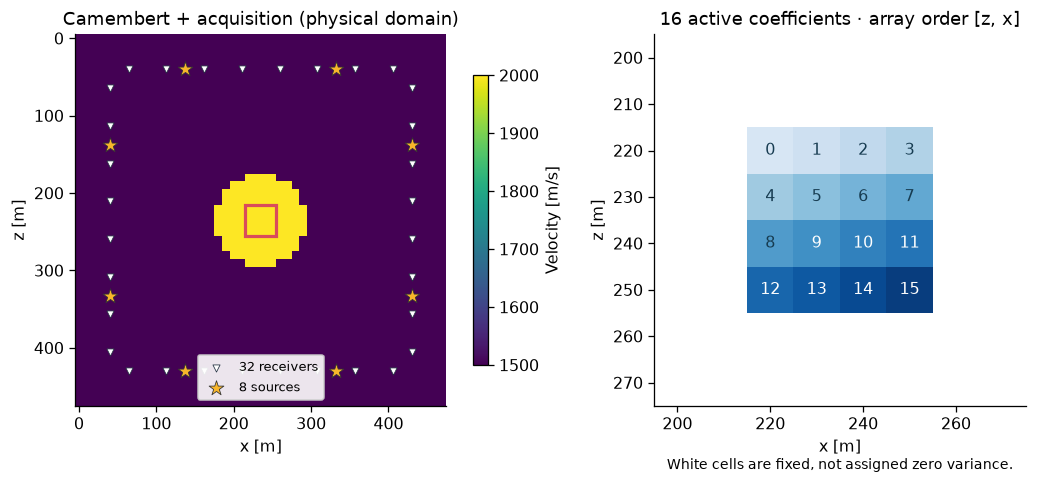

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.1), layout="constrained")
extent = [float(x[0]-5), float(x[-1]+5), float(z[-1]+5), float(z[0]-5)]
image = axes[0].imshow(velocity_true, extent=extent, cmap="viridis", vmin=1500, vmax=2000)
sources = np.asarray(acquisition.sources_m); receivers = np.asarray(acquisition.receivers_m)
axes[0].scatter(receivers[:, 1], receivers[:, 0], marker="v", s=20,
                c="white", edgecolors="#273545", linewidths=.5, label="32 receivers")
axes[0].scatter(sources[:, 1], sources[:, 0], marker="*", s=95,
                c="#f8b62b", edgecolors="#333333", linewidths=.5, label="8 sources")
axes[0].add_patch(Rectangle((215, 215), 40, 40, fill=False, edgecolor="#d94c5b", lw=2))
axes[0].set(title="Camembert + acquisition (physical domain)", xlabel="x [m]", ylabel="z [m]")
axes[0].legend(loc="lower center", fontsize=8, framealpha=.9)
fig.colorbar(image, ax=axes[0], shrink=.78, label="Velocity [m/s]")
indices = torch.full(grid.shape, float("nan"), dtype=torch.float64)
indices[active] = torch.arange(n_active, dtype=torch.float64)
im = axes[1].imshow(indices[20:28, 20:28], extent=[195, 275, 275, 195],
                     cmap="Blues", vmin=-3, vmax=16)
for row in range(22, 26):
    for col in range(22, 26):
        axes[1].text(float(x[col]), float(z[row]), str(int(indices[row, col])),
                     ha="center", va="center", color="white" if indices[row, col] > 8 else "#173c51")
axes[1].set(title="16 active coefficients · array order [z, x]", xlabel="x [m]", ylabel="z [m]")
axes[1].text(.5, -.17, "White cells are fixed, not assigned zero variance.",
             transform=axes[1].transAxes, ha="center", fontsize=9)
plt.show()

**Likelihood convention.** The synthetic realization above is noise-free, while the likelihood assumes independent errors $\operatorname{Re}\epsilon,\operatorname{Im}\epsilon\sim N(0,\sigma^2)$; hence $E|\epsilon|^2=2\sigma^2$. Here $\sigma$ is 0.2% of the complex data RMS. Using this declared value in $W=1/\sigma$ makes the covariance interpretable under that model. Arbitrary loss normalization changes the inferred uncertainty. Same-grid data exclude discretization and modeling error; no coverage claim follows from this example.

## 3. Check the derivatives before interpreting curvature

The active direction is normalized in physical $m=v^{-2}$ coordinates. We compare an exact Hessian–vector product with a centered finite difference of the source-streamed gradient, and compare exact/GN actions at the exact-fit point. These tests exercise the implicit solves, not a dense autograd trace through all source wavefields.

In [5]:
def relative_error(actual, reference):
    return float((actual-reference).norm()/reference.norm().clamp_min(torch.finfo(torch.float64).tiny))

def active_gradient(m):
    leaf = m.detach().clone().requires_grad_()
    gradient = torch.zeros_like(leaf)
    for loss in objective.iter_data_losses(leaf, source_batch_size):
        gradient += torch.autograd.grad(loss, leaf)[0].detach()
    return gradient[active]

direction = torch.randn(n_active, dtype=torch.float64)
direction /= direction.norm()
step_m = float(m_background.mean())*1e-3
perturbation = curvature_bad.inject(direction)
exact_action = curvature_bad.exact_hvp(direction)
finite_difference = (active_gradient(m_background+step_m*perturbation)
                     - active_gradient(m_background-step_m*perturbation))/(2*step_m)
fd_error = relative_error(exact_action, finite_difference)
zero_residual_error = relative_error(curvature_map.exact_hvp(direction),
                                     curvature_map.data_gn_hvp(direction))
stationary_gradient = active_gradient(m_star)
assert fd_error < 1e-5
assert zero_residual_error < 1e-8
assert float(stationary_gradient.abs().max()) < 1e-9
print(f"Exact HVP vs gradient finite difference: {fd_error:.3e}")
print(f"Exact vs GN at exact fit:              {zero_residual_error:.3e}")
print(f"Exact-fit active gradient max |g|:     {float(stationary_gradient.abs().max()):.3e}")

Exact HVP vs gradient finite difference: 8.649e-10
Exact vs GN at exact fit:              0.000e+00
Exact-fit active gradient max |g|:     0.000e+00


## 4. Inspect exact and Gauss–Newton Hessians

For these **16 parameters only**, `explicit_matrix` applies each operator to one basis vector at a time. Its 8 KiB guard covers the resulting small matrix and vectors; Helmholtz factors and HVP workspace have separate costs. Do not scale dense assembly to a full inversion grid.

Physical-$m$ Hessian entries have units m⁴/s⁴ and can be very large. For legible comparisons, set $D=\operatorname{diag}(s_m)$ with prior standard deviations $s_m=0.1m_\star$ and show $DHD$, the dimensionless Hessian in $q=D^{-1}(m-m_\star)$ coordinates. **The same scaling and color limits** are used for both matrices.

In [6]:
prior_std_m = 0.1*m_star[active]
prior_precision = prior_std_m.square().reciprocal()
matrix_start = time.perf_counter()
G_bad = explicit_matrix(curvature_bad.data_gn_hvp, n_active, max_bytes=8*1024)
H_bad = explicit_matrix(curvature_bad.exact_hvp, n_active, max_bytes=8*1024)
G_map = explicit_matrix(curvature_map.data_gn_hvp, n_active, max_bytes=8*1024)

scale_hessian = lambda H: prior_std_m[:, None]*H*prior_std_m[None, :]
Gq_bad, Hq_bad, Gq_map = map(scale_hessian, (G_bad, H_bad, G_map))
symmetry_error = float((H_bad-H_bad.T).norm()/H_bad.norm())
# Symmetrize only for tiny roundoff before a symmetric eigensolver / factorization.
assert symmetry_error < 1e-8
sym = lambda H: (H+H.T)/2
eig_gn = torch.linalg.eigvalsh(sym(Gq_bad))
eig_exact = torch.linalg.eigvalsh(sym(Hq_bad))
assert float(eig_gn.min()) >= -1e-10*float(eig_gn.abs().max())
nonzero_difference = relative_error(H_bad, G_bad)
assert nonzero_difference > 1e-3
print(f"Three 16×16 diagnostics: {time.perf_counter()-matrix_start:.2f} s")
print(f"Exact Hessian relative asymmetry: {symmetry_error:.3e}")
print(f"Nonzero-residual ||H−G||/||G||:   {nonzero_difference:.3e}")
print(f"Smallest eigenvalue, exact/GN:   {float(eig_exact.min()):.3e} / {float(eig_gn.min()):.3e}")

Three 16×16 diagnostics: 28.45 s
Exact Hessian relative asymmetry: 1.059e-15
Nonzero-residual ||H−G||/||G||:   3.957e-01
Smallest eigenvalue, exact/GN:   8.532e-01 / 3.410e-11


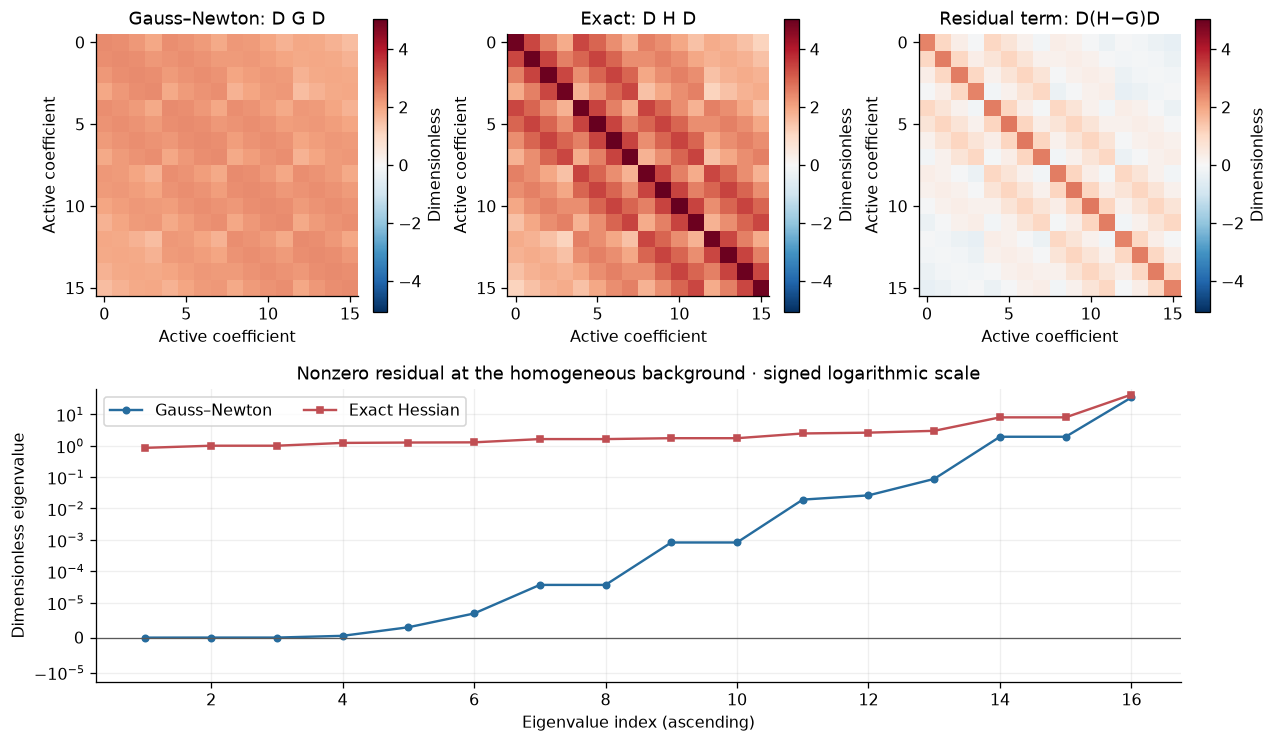

In [7]:
fig = plt.figure(figsize=(11, 6.6), layout="constrained")
gs = fig.add_gridspec(2, 3, height_ratios=(1, .8))
limit = max(float(Gq_bad.abs().max()), float(Hq_bad.abs().max()))
for col, (matrix, title) in enumerate(((Gq_bad, "Gauss–Newton: D G D"),
                                      (Hq_bad, "Exact: D H D"),
                                      (Hq_bad-Gq_bad, "Residual term: D(H−G)D"))):
    ax = fig.add_subplot(gs[0, col])
    im = ax.imshow(matrix, cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set(title=title, xlabel="Active coefficient", ylabel="Active coefficient")
    ax.set_xticks([0, 5, 10, 15]); ax.set_yticks([0, 5, 10, 15])
    fig.colorbar(im, ax=ax, shrink=.8, label="Dimensionless")
ax = fig.add_subplot(gs[1, :])
ax.plot(range(1, 17), eig_gn, "o-", label="Gauss–Newton", color="#266c9e", ms=4)
ax.plot(range(1, 17), eig_exact, "s-", label="Exact Hessian", color="#c04e53", ms=4)
ax.axhline(0, color="0.35", lw=.8)
ax.set_yscale("symlog", linthresh=1e-5)
minimum = min(float(eig_gn.min()), float(eig_exact.min()))
maximum = max(float(eig_gn.max()), float(eig_exact.max()))
ax.set_ylim(1.3*minimum if minimum < -1e-5 else -2e-5, 1.5*maximum)
ax.set(xlabel="Eigenvalue index (ascending)", ylabel="Dimensionless eigenvalue",
       title="Nonzero residual at the homogeneous background · signed logarithmic scale")
ax.legend(ncol=2); ax.grid(alpha=.2)
plt.show()

**Read the spectrum.** Gauss–Newton is positive semidefinite up to roundoff. Negative exact-Hessian eigenvalues, when present, describe local nonconvexity; inverting that matrix would give invalid negative variances. The printed minimum eigenvalues identify the sign in your run. Positive curvature alone does not make the homogeneous reference a stationary MAP estimate. We use its exact Hessian as a curvature diagnostic.

At the exact-fit reference the residual term vanishes. The prior is centered at that same reference, so the data-plus-prior gradient is zero and the prior makes the posterior precision positive definite. Thus the exact Laplace and GN local covariances coincide in this controlled case. This is a useful validation limit; real noisy, nonlinear inversions generally do not share it.

## 5. Apply the covariance without assembling it

`LocalGaussian` applies **data-only** GN curvature plus the supplied proper prior, exactly once. The diagonal prior is independent in physical $m$ coordinates; it is not an optimizer damping term. `covariance_action(b)` solves $(G+P)c=b$ by preconditioned CG, checking the true residual. It returns physical-$m$ covariance actions in s⁴/m⁴.

For this small reference only, we form a dense covariance in the better-scaled $q$ coordinates, then transform back: $C_m=D(I+DGD)^{-1}D$. It serves as an independent linear-algebra comparison with the matrix-free API.

In [8]:
posterior = LocalGaussian(curvature_map, prior_precision,
                           solve_config=CGConfig(rtol=1e-10, atol=0, maxiter=80))
precision_q = torch.eye(n_active, dtype=torch.float64) + sym(Gq_map)
chol = torch.linalg.cholesky(precision_q)  # explicit SPD check on the tiny reference
covariance_q = torch.cholesky_inverse(chol)
covariance_m = prior_std_m[:, None]*covariance_q*prior_std_m[None, :]

probe = torch.linspace(1., 2., n_active, dtype=torch.float64)
covariance_product = posterior.covariance_action(probe)
covariance_report = posterior.last_solve
inverse_error = relative_error(covariance_product, covariance_m@probe)
assert inverse_error < 1e-8
assert covariance_report.converged
assert bool((covariance_m.diagonal() > 0).all())
assert bool((covariance_m.diagonal() <= prior_std_m.square()*(1+1e-10)).all())
print(f"Matrix-free vs tiny explicit inverse: {inverse_error:.3e}")
print(f"CG iterations: {covariance_report.iterations}; true relative residual: "
      f"{covariance_report.relative_residual:.3e}")
print(f"CG solution-error bound ||r||/min(P): {covariance_report.solution_error_bound:.3e}")
print("The bound concerns the covariance linear solve, not wave/model approximation error.")

Matrix-free vs tiny explicit inverse: 2.319e-12
CG iterations: 5; true relative residual: 5.527e-12
CG solution-error bound ||r||/min(P): 2.116e-26
The bound concerns the covariance linear solve, not wave/model approximation error.


## 6. Report uncertainty in useful units

The covariance is in squared-slowness coordinates. To display **velocity** uncertainty, use the first-order delta method,

$$\frac{\partial v}{\partial m}=-\tfrac12m^{-3/2},\qquad
s_v\approx\left|\frac{\partial v}{\partial m}\right|\sqrt{\operatorname{diag}C_m}.$$

This is a local Gaussian approximation, not an exact nonlinear transformation of a posterior. Positivity bounds and nonlinear tails are not represented by these intervals. The maps below mask inactive cells with `NaN`: those cells were held fixed, so their uncertainty was **not inferred**. The profile shows pointwise $\pm1.96s_v$ intervals, not a simultaneous 95% band or a demonstrated coverage rate.

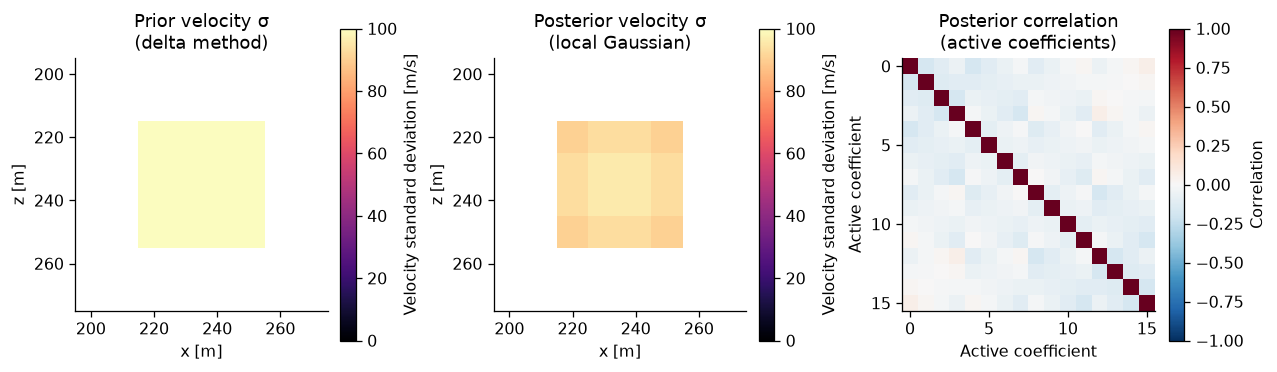

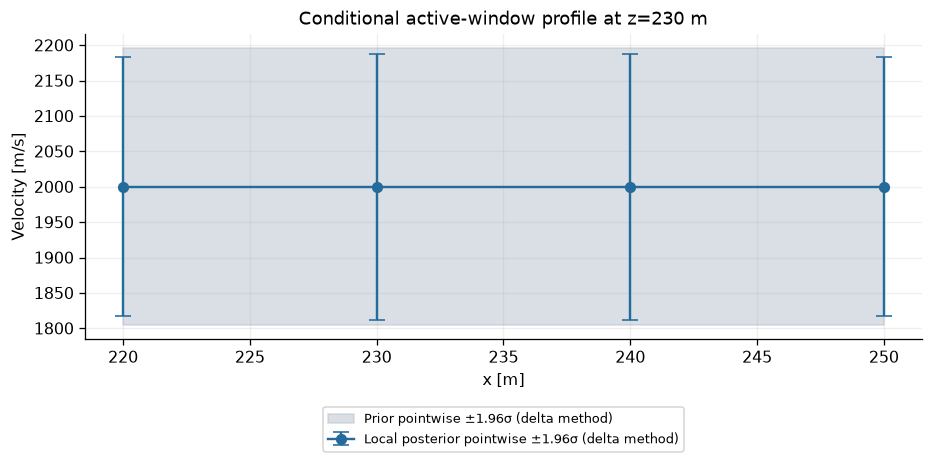

Prior velocity σ: 100.00–100.00 m/s
Posterior velocity σ: 90.45–96.05 m/s


In [9]:
std_m = covariance_m.diagonal().sqrt()
velocity_derivative = 0.5*m_star[active].pow(-1.5)
prior_std_v = velocity_derivative*prior_std_m
posterior_std_v = velocity_derivative*std_m
prior_map = torch.full_like(m_star, float("nan"))
posterior_map = torch.full_like(m_star, float("nan"))
prior_map[active] = prior_std_v
posterior_map[active] = posterior_std_v
correlation = covariance_m/(std_m[:, None]*std_m[None, :])

fig, axes = plt.subplots(1, 3, figsize=(11, 3.7), layout="constrained")
for ax, data, title in zip(axes[:2], (prior_map, posterior_map),
                          ("Prior velocity σ\n(delta method)", "Posterior velocity σ\n(local Gaussian)")):
    im = ax.imshow(data[20:28, 20:28], extent=[195, 275, 275, 195],
                   cmap="magma", vmin=0, vmax=float(prior_std_v.max()))
    ax.set(title=title, xlabel="x [m]", ylabel="z [m]")
    fig.colorbar(im, ax=ax, shrink=.75, label="Velocity standard deviation [m/s]")
im = axes[2].imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
axes[2].set(title="Posterior correlation\n(active coefficients)", xlabel="Active coefficient", ylabel="Active coefficient")
axes[2].set_xticks([0, 5, 10, 15]); axes[2].set_yticks([0, 5, 10, 15])
fig.colorbar(im, ax=axes[2], shrink=.75, label="Correlation")
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.9), layout="constrained")
row = 23
profile_x = x[22:26].numpy()
mean_v = velocity_true[row, 22:26].numpy()
prior_profile = prior_map[row, 22:26].numpy()
posterior_profile = posterior_map[row, 22:26].numpy()
ax.fill_between(profile_x, mean_v-1.96*prior_profile, mean_v+1.96*prior_profile,
                 color="#bbc5cf", alpha=.55, label="Prior pointwise ±1.96σ (delta method)")
ax.errorbar(profile_x, mean_v, yerr=1.96*posterior_profile, fmt="o-", capsize=5,
             color="#246b9b", label="Local posterior pointwise ±1.96σ (delta method)")
ax.set(xlabel="x [m]", ylabel="Velocity [m/s]",
       title=f"Conditional active-window profile at z={float(z[row]):g} m")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.20)); ax.grid(alpha=.2)
plt.show()
print(f"Prior velocity σ: {float(prior_std_v.min()):.2f}–{float(prior_std_v.max()):.2f} m/s")
print(f"Posterior velocity σ: {float(posterior_std_v.min()):.2f}–{float(posterior_std_v.max()):.2f} m/s")

## 7. Optional: estimate the diagonal with streamed probes

At larger scale, never construct the dense covariance. Hutchinson probes estimate its diagonal using $z\odot C z$. The API reports **Monte Carlo standard error** separately from inner CG error. Eight probes below illustrate the interface; they are not enough to assume a precise estimate. Negative finite-sample estimates are possible and should be reported rather than silently clipped into false certainty.

This extra calculation is **off by default** because every probe requires several curvature actions. Enable it to compare with the tiny exact reference. Wavefield memory remains source-batched; computational cost still increases with probe count and CG iterations.

In [10]:
RUN_STOCHASTIC_DIAGONAL = False
if RUN_STOCHASTIC_DIAGONAL:
    estimate = posterior.diagonal_estimate(probes=8, seed=37)
    exact_diagonal = covariance_m.diagonal()
    fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
    # A common physical scale improves readability without changing the estimator.
    variance_unit = float(prior_std_m.square().mean())
    ax.errorbar(range(n_active), (estimate.mean/variance_unit).numpy(),
                 yerr=(estimate.standard_error/variance_unit).numpy(), fmt="o", capsize=3,
                 label="8 probes ±1 Monte Carlo standard error")
    ax.plot(range(n_active), (exact_diagonal/variance_unit).numpy(), "k-", label="Tiny exact reference")
    ax.set(xlabel="Active coefficient", ylabel="Variance / mean prior variance",
           title="Stochastic inverse diagonal · Monte Carlo error is not posterior uncertainty")
    ax.legend(fontsize=8); ax.grid(alpha=.2); plt.show()
    print(f"Maximum inner solve error bound: {estimate.max_solve_error_bound:.3e}")
else:
    print("Optional probe estimator skipped. Set RUN_STOCHASTIC_DIAGONAL=True to run it.")

Optional probe estimator skipped. Set RUN_STOCHASTIC_DIAGONAL=True to run it.


## Checks and next steps

The assertions test derivative finite differences, exact/GN equality at zero residual, symmetry, GN positivity, an SPD posterior precision, and covariance inverse actions. They validate this fixed-discretization problem and its implementation; they do not certify a real-data posterior.

For a scientific uncertainty study, obtain a converged MAP estimate under a justified noise model and prior, retain acquisition/model errors in the interpretation, enlarge the active region, and check mesh/PML convergence. At nonzero residual, compare exact and GN actions and verify posterior positivity before any exact Laplace interpretation. The prior, whitening and reference point are part of the result and must be recorded.

For large grids, use `covariance_action`, streamed `diagonal_estimate`, or bounded prior-metric `leading_modes` from the [uncertainty guide](../guides/uncertainty.md). Storage can be bounded, but many Helmholtz solves can still be expensive. Recreate `Curvature` whenever the model, acquisition, weights or observations change.

In [11]:
checks = {
    "HVP finite-difference relative error": fd_error,
    "Exact/GN exact-fit relative error": zero_residual_error,
    "Exact Hessian symmetry relative error": symmetry_error,
    "Covariance action relative error": inverse_error,
    "Covariance CG true relative residual": covariance_report.relative_residual,
}
rows = "\n".join(f"| {name} | {value:.3e} |" for name, value in checks.items())
display(Markdown("| Executed check | Observed value |\n|---|---:|\n"+rows))
print(f"Elapsed notebook calculation time: {time.perf_counter()-START:.2f} s")
print("Result: conditional local Gaussian algebra checked; no coverage or full reconstruction claim.")

| Executed check | Observed value |
|---|---:|
| HVP finite-difference relative error | 8.649e-10 |
| Exact/GN exact-fit relative error | 0.000e+00 |
| Exact Hessian symmetry relative error | 1.059e-15 |
| Covariance action relative error | 2.319e-12 |
| Covariance CG true relative residual | 5.527e-12 |

Elapsed notebook calculation time: 39.82 s
Result: conditional local Gaussian algebra checked; no coverage or full reconstruction claim.
